## Data Preprocessing & EDA – Ames Housing

#### Installing the needed libraries

In [2]:
!pip install kagglehub
!pip install pandas  
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn
!pip install tensorflow

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 572.3 kB/s eta 0:00:17
   -- ------------------------------------- 0.5/9.9 MB 572.3 kB/s eta 0:00:17
   --- ------------------------------------ 0.8/9.9 MB 549.4 kB/s eta 0:00:17
   --- ------------------------------------ 0.8/9.9 MB 549.4 kB/s eta 0:00:17
   --- ------------------------------------ 0.8/9.9 MB 549.4 kB/s eta 0:00:17
   ---- ----------------------------------- 1.0/9.9 MB 512.7 kB/s eta 0:00:18
   ---- ----------------------------------- 1.0/9

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 442.8 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/9.5 MB 442.8 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/9.5 MB 456.1 kB/s eta 0:00:20
   --- ------------------------------------ 0.8/9.5 MB 456.1 kB/s eta 0:00:20
   --- ------------------------------------ 0.8/9.5 MB 456.1 kB/s eta 0:00:20
   ---- ----------------------------------- 1.0/9.5 MB 452.5 kB/s eta 0:00:19
   ---- ----------------------------------- 1.0/9

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 209.9 kB/s eta 0:00:37
   -- ------------------------------------- 0.5/8.3 MB 209.9 kB/s eta 0:00:37
   -- ------------------------------------- 0.5/8.3 MB 209.9 kB/s eta 0:00:37
   -- -

ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)
ERROR: No matching distribution found for tensorflow


In [6]:
!pip install ipywidgets


   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/914.9 kB ? eta -:

### Importing the libraries that will be used 

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import warnings
warnings.filterwarnings('ignore')

### Loading the saved data from csv file

In [12]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
# Keep a copy of the original test IDs if needed
test_ids = test['Id'] if 'Id' in test.columns else None

### For EDA we only work with the training set

In [13]:
df = train.copy()

### Separate target


In [14]:
y = df['SalePrice']
X = df.drop(columns=['SalePrice', 'Id'], errors='ignore')

### High‑level missing value analysis

In [15]:
missing = X.isnull().sum()
missing_pct = (missing / len(X)) * 100
missing_table = pd.DataFrame({'missing': missing, 'pct': missing_pct})
print("Top 10 features with highest missing %:\n", missing_table[missing_table['missing'] > 0].sort_values('pct', ascending=False).head(10))

Top 10 features with highest missing %:
               missing        pct
PoolQC           1453  99.520548
MiscFeature      1406  96.301370
Alley            1369  93.767123
Fence            1179  80.753425
MasVnrType        872  59.726027
FireplaceQu       690  47.260274
LotFrontage       259  17.739726
GarageType         81   5.547945
GarageYrBlt        81   5.547945
GarageFinish       81   5.547945


### Dropping features >80% missing; impute the rest

In [16]:
cols_to_drop = missing_table[missing_table['pct'] > 80].index.tolist()
print(f"Dropping {cols_to_drop} (missing >80%)")
X.drop(columns=cols_to_drop, inplace=True, errors='ignore')

Dropping ['Alley', 'PoolQC', 'Fence', 'MiscFeature'] (missing >80%)


### Define preprocessing pipelines

In [17]:
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

### For numeric: median imputation + outlier capping (IQR) before scaling
####  We'll build a custom transformer for outlier capping

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# Custom outlier capping transformer
class OutlierCapper(BaseEstimator, TransformerMixin):
    """Cap numeric features at IQR * factor beyond Q1/Q3."""
    def __init__(self, factor=1.5):
        self.factor = factor
        
    def fit(self, X, y=None):
        # Calculate percentiles along columns (axis=0)
        Q1 = np.percentile(X, 25, axis=0)
        Q3 = np.percentile(X, 75, axis=0)
        IQR = Q3 - Q1
        self.lower_ = Q1 - self.factor * IQR
        self.upper_ = Q3 + self.factor * IQR
        return self
        
    def transform(self, X):
        # Clip values to the calculated upper and lower boundaries
        X_capped = np.clip(X, self.lower_, self.upper_)
        return X_capped

# Define your feature list names (Example placeholders)
numeric_features = ['age', 'salary'] 
categorical_features = ['gender', 'city']

# Numeric pipeline with fixed quotes
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('capper', OutlierCapper(factor=1.5)),
    ('scaler', StandardScaler())
])

# Categorical pipeline with fixed quotes and updated sparse argument
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=None)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Column preprocessor with fixed quotes
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'  # drops any columns not explicitly listed
)

### Listing the columns available


In [21]:
print(X.columns.tolist())


['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'Y

## Key EDA Visuals
### Visual 1: Distribution of SalePrice after log transformation

FileNotFoundError: [Errno 2] No such file or directory: 'visuals/ames_saleprice_dist.png'

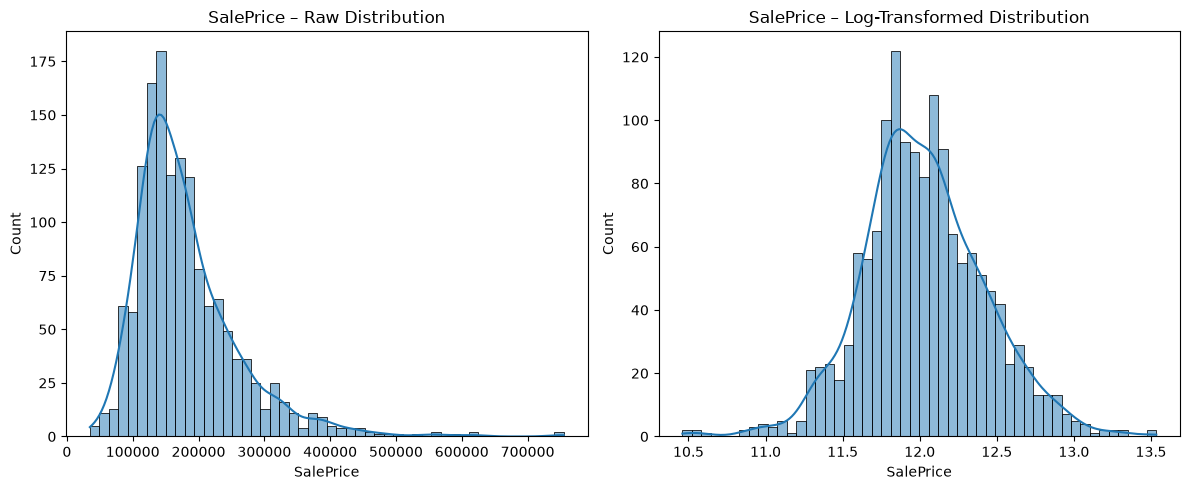

In [28]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(y, kde=True, bins=50)
plt.title('SalePrice – Raw Distribution')

plt.subplot(1, 2, 2)
log_y = np.log1p(y)
sns.histplot(log_y, kde=True, bins=50)
plt.title('SalePrice – Log-Transformed Distribution')
plt.tight_layout()
plt.savefig('visuals/ames_saleprice_dist.png', dpi=150)
plt.close()

In [30]:
print("Available columns in X:", X.columns.tolist())
print("Data type of X:", type(X))
print("First 2 rows of X:")
print(X.head(2))


Available columns in X: ['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',

In [31]:
# Change this to match your actual housing columns
numeric_features = ['LotArea', 'GrLivArea', 'OverallQual', 'YearBuilt'] 


### Visual 2: Correlation heatmap of top 20 most correlated numeric features with SalePrice

FileNotFoundError: [Errno 2] No such file or directory: 'visuals/ames_correlation_heatmap.png'

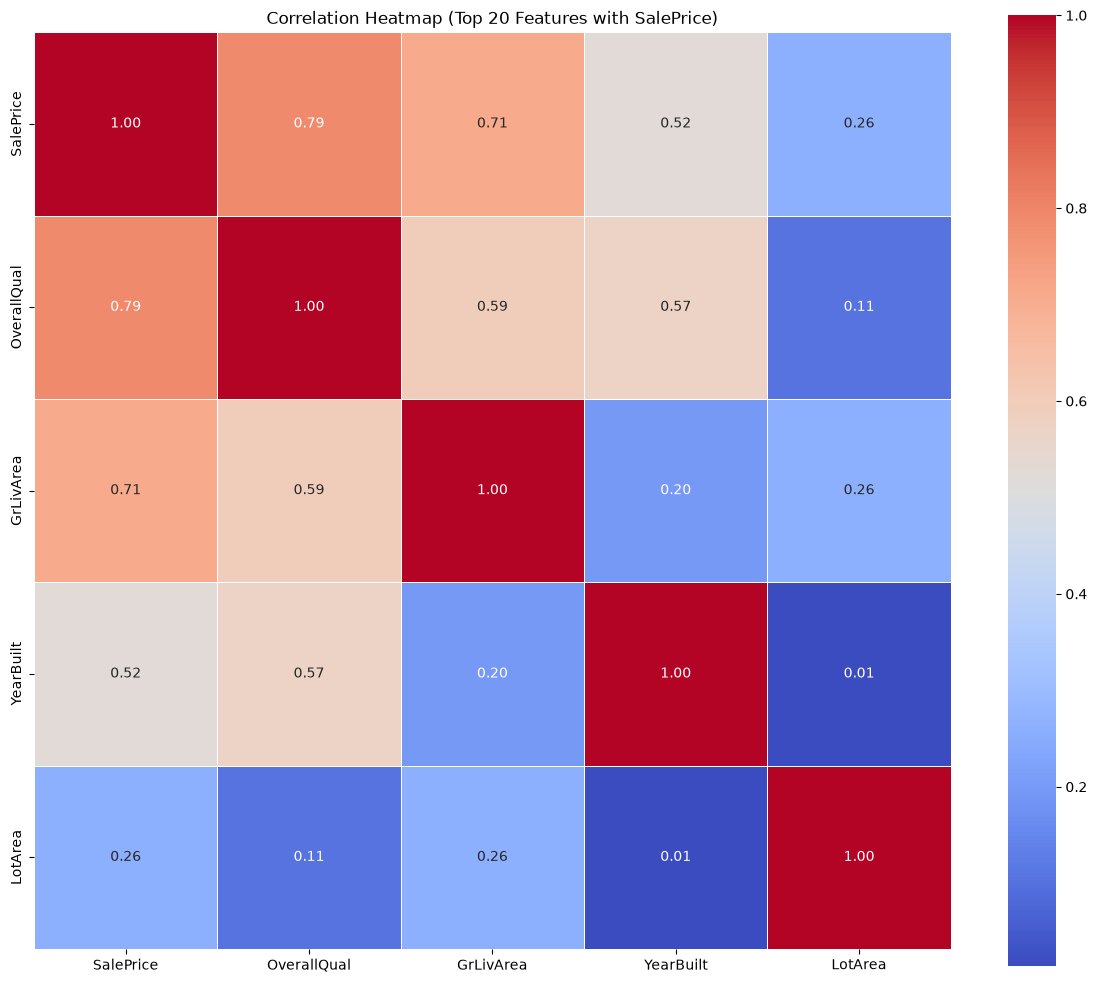

In [33]:
corr_df = pd.concat([X[numeric_features].copy(), y.rename('SalePrice')], axis=1)
corr_matrix = corr_df.corr()
top_features = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(20).index
plt.figure(figsize=(12, 10))
sns.heatmap(corr_df[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap (Top 20 Features with SalePrice)')
plt.tight_layout()
plt.savefig('visuals/ames_correlation_heatmap.png', dpi=150)
plt.close()
